In [1]:
import pandas as pd
import ast
from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df= dataset['train'].to_pandas()

df['job_posted_date']= pd.to_datetime(df['job_posted_date'])
df['job_skills']= df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\Tanu\anaconda3\envs\python_project\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import seaborn as sns


In [3]:
df_DA_US= df[(df['job_title_short']=='Data Analyst')& (df['job_country']=='United States')].copy()

df_DA_US = df_DA_US.dropna(subset=['salary_year_avg'])


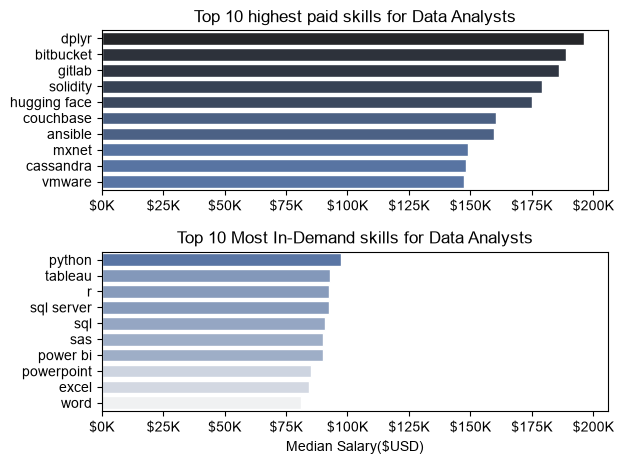

In [10]:
df_DA_US= df_DA_US.explode('job_skills')
df_DA_US_group = df_DA_US.groupby('job_skills')['salary_year_avg'].agg(['count','median'])
df_DA_top_pay = df_DA_US_group.sort_values(by='median',ascending=False).head(10)
df_DA_skills = df_DA_US_group.sort_values(by='count',ascending= False).head(10).sort_values(by='median',ascending=False)


fig, ax = plt.subplots(2,1)

sns.set_theme(style='ticks')
sns.barplot(data=df_DA_top_pay, x= 'median', y=df_DA_top_pay.index,ax=ax[0],hue='median',palette='dark:b_r')
ax[0].legend().remove()
#df_DA_top_pay[::-1].plot(kind='barh', y = 'median', ax= ax[0],legend= False)
ax[0].set_title('Top 10 highest paid skills for Data Analysts')
ax[0].set_ylabel('')
ax[0].set_xlabel('')
ax[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _ : f'${int(x/1000)}K'))


sns.barplot(data=df_DA_skills, x= 'median', y=df_DA_skills.index,ax=ax[1],hue='median',palette='light:b')
ax[1].legend().remove()
#df_DA_skills[::-1].plot(kind='barh', y = 'median', ax= ax[1],legend = False)
ax[1].set_title('Top 10 Most In-Demand skills for Data Analysts')
ax[1].set_ylabel('')
ax[1].set_xlabel('Median Salary($USD)')
ax[1].set_xlim(ax[0].get_xlim())
ax[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _ : f'${int(x/1000)}K'))

fig.tight_layout()
plt.show()


Text(12.444444444444445, 0.5, 'No. of Jobs')

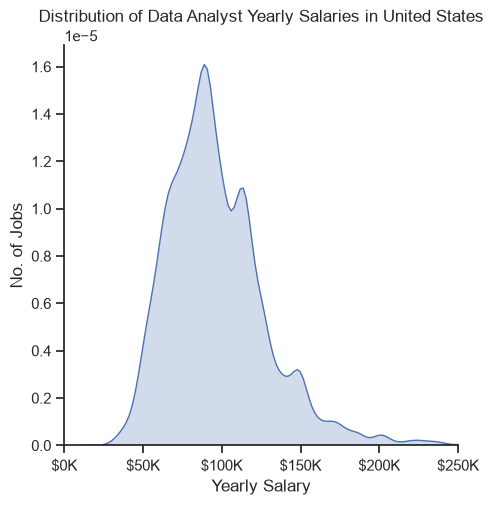

In [12]:
sns.displot(df_DA_US['salary_year_avg'],kind='kde',fill = True)
#df_DA_US['salary_year_avg'].plot(kind='hist',bins=40,edgecolor='black')
plt.xlim(0,250000)

ax = plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}K'))

plt.title('Distribution of Data Analyst Yearly Salaries in United States')
plt.xlabel('Yearly Salary')
plt.ylabel('No. of Jobs')

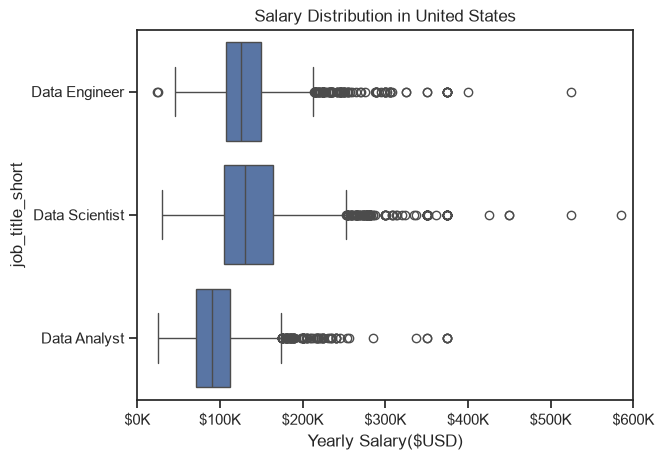

In [14]:
job_titles= ['Data Analyst','Data Engineer', 'Data Scientist']

df_US= df[(df['job_title_short'].isin(job_titles))& (df['job_country']=='United States')].copy()
df_US = df_US.dropna(subset=['salary_year_avg'])

sns.boxplot(data=df_US,x='salary_year_avg',y='job_title_short')

plt.title('Salary Distribution in United States')
plt.xlabel('Yearly Salary($USD)')
ax=plt.gca()
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos : f'${int(x/1000)}K'))
plt.xlim(0,600000)
plt.show()